In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from scipy.stats import pearsonr

#load the csv file
df = pd.read_csv("dry curly hair data/Extension_Dry_2000mmmin_C_sorted_by_strain.csv")
print(df)

     Record  Strain (%)  Stress (MPa)
0         1         0.0           0.3
1         1         0.0          -0.1
2         1         0.1           0.0
3         1         0.2           0.1
4         1         0.5           0.3
..      ...         ...           ...
270      25         1.2           0.4
271      25         1.7           0.5
272      25         2.3           1.2
273      25         2.9           0.9
274      25         3.6           2.4

[275 rows x 3 columns]


In [ ]:
#Convert columns to numbers
df["Strain (%)"] = pd.to_numeric(df["Strain (%)"], errors='coerce')
df["Stress (MPa)"] = pd.to_numeric(df["Stress (MPa)"], errors='coerce')
df = df.dropna(subset=["Strain (%)", "Stress (MPa)"])  # Drop rows with NaN values in these columns

#Sort by strain
df = df.sort_values("Strain (%)")

#Check the data
print(df.head())
print(df.info())

    Record  Strain (%)  Stress (MPa)
0        1         0.0           0.3
1        1         0.0          -0.1
22       3         0.0          -0.1
23       3         0.0          -0.2
34       4         0.0           0.1
<class 'pandas.core.frame.DataFrame'>
Index: 275 entries, 0 to 219
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Record        275 non-null    int64  
 1   Strain (%)    275 non-null    float64
 2   Stress (MPa)  275 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 8.6 KB
None


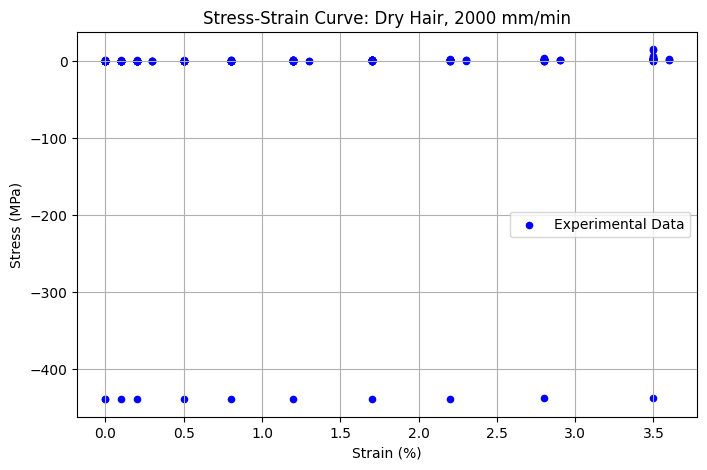

In [ ]:
plt.figure(figsize=(8, 5)) #Raw stress-strain data
plt.scatter(df["Strain (%)"], df["Stress (MPa)"], s=20, label = "Experimental Data", color='blue')

plt.xlabel("Strain (%)")
plt.ylabel("Stress (MPa)")
plt.title("Stress-Strain Curve: Dry Hair, 2000 mm/min")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
mean_df = (df.groupby("Strain (%)")["Stress (MPa)"].agg(['mean', 'std']).reset_index())
print(mean_df)

    Strain (%)       mean        std
0          0.0 -17.462000  86.857979
1          0.1 -17.604000  87.791237
2          0.2 -22.140000  98.119006
3          0.3  -0.100000   0.173205
4          0.5 -17.472000  87.818480
5          0.8 -17.328000  87.765305
6          1.2 -18.704348  91.512525
7          1.3   0.250000   0.070711
8          1.7 -17.028000  87.765490
9          2.2 -19.159091  93.594936
10         2.3   0.833333   0.404145
11         2.8 -18.563636  93.596548
12         2.9   0.800000   0.264575
13         3.5 -16.686364  93.914507
14         3.6   1.566667   0.850490


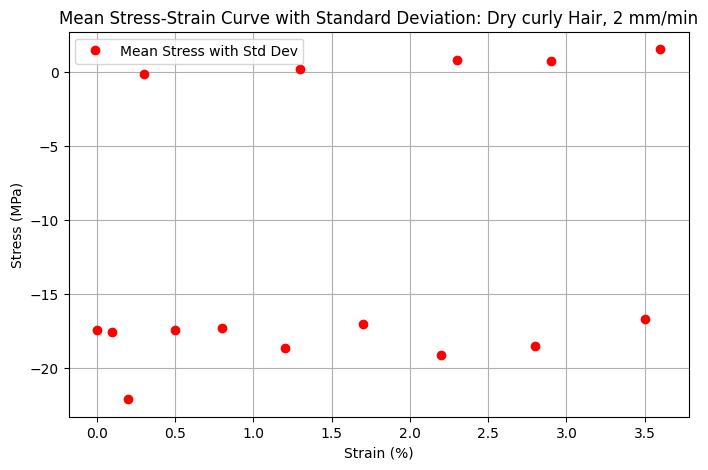

In [ ]:
plt.figure(figsize=(8, 5)) 
plt.errorbar(mean_df["Strain (%)"], mean_df["mean"], fmt='o', label='Mean Stress with Std Dev', color='red', capsize=3)

plt.xlabel("Strain (%)")
plt.ylabel("Stress (MPa)")
plt.title("Mean Stress-Strain Curve with Standard Deviation: Dry curly Hair, 2 mm/min")
plt.legend()
plt.grid(True)
plt.show()